# Test A/B: ¿qué oferta vende más, "10% de descuento" o "Envío gratis"?

**Contexto.** Una tienda online muestra una oferta en la página de producto. El equipo de marketing quiere sustituir el
clásico *10% de descuento* (variante **A**, control) por *Envío gratis en pedidos ≥ 40 €* (variante **B**).

**Pregunta de negocio.** ¿La oferta B aumenta la conversión **y** el beneficio por visitante lo suficiente como para lanzarla?

| | Definición |
|---|---|
| **Métrica principal** | Tasa de conversión = compradores / visitantes |
| **Métricas secundarias** | Ingreso por visitante (RPV), ticket medio (AOV), beneficio por visitante |
| **Hipótesis** | H0: conv(B) = conv(A) · H1: conv(B) ≠ conv(A) (bilateral, α = 0,05, potencia = 80%) |
| **Unidad de aleatorización** | Visitante, reparto 50/50 durante 28 días |

> Los datos son **simulados** (`src/generate_data.py`) con un efecto real conocido, para poder comprobar que el análisis lo recupera.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
import ab_stats as ab

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {"A": "#2a78d6", "B": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "figure.dpi": 110,
})
pd.set_option("display.float_format", "{:,.4f}".format)

df = pd.read_csv(ROOT / "data" / "experiment_data.csv", parse_dates=["date"])
df.head()

,user_id,date,variant,device,user_type,source,converted,revenue,profit
0,1,2026-09-09,A,mobile,nuevo,social,0,0.0000,0.0000
1,2,2026-09-10,B,mobile,recurrente,organico,0,0.0000,0.0000
2,3,2026-09-04,A,desktop,recurrente,paid,1,48.4000,16.1300
3,4,2026-09-04,A,mobile,recurrente,paid,0,0.0000,0.0000
4,5,2026-09-15,B,desktop,recurrente,organico,1,25.0700,10.0300


## 1. Diseño del experimento: ¿cuántos visitantes necesitamos?

Antes de lanzar el test se fija el **efecto mínimo detectable (MDE)**: el lift más pequeño que merece la pena para el negocio.
Con una conversión histórica de ~3,6% y un MDE relativo del 10%, la fórmula del z-test de dos proporciones nos da el tamaño por variante.

In [2]:
baseline_cr = 0.036
for mde in [0.05, 0.10, 0.15, 0.20]:
    n = ab.sample_size_proportions(baseline_cr, mde)
    print(f"MDE {mde:>4.0%}  ->  {n:>8,} visitantes por variante  ({2 * n:,} en total)")

MDE   5%  ->   172,180 visitantes por variante  (344,360 en total)
MDE  10%  ->    44,051 visitantes por variante  (88,102 en total)
MDE  15%  ->    20,024 visitantes por variante  (40,048 en total)
MDE  20%  ->    11,513 visitantes por variante  (23,026 en total)


Con un MDE del 10% necesitamos **~44.000 visitantes por variante**. Con ~3.200 visitantes/día eso son 28 días,
que además cubren 4 semanas completas (evita sesgos por día de la semana). **La duración se fija antes de empezar y no se para el test antes de tiempo.**

## 2. Sanity checks

### 2.1 Sample Ratio Mismatch (SRM)
Si el reparto real se aleja del 50/50 esperado más de lo que explica el azar, la asignación está rota (bugs, bots, redirecciones) y
**ningún resultado sería fiable**. Se comprueba con un test chi-cuadrado; la alarma salta con p < 0,001.

In [3]:
counts = df["variant"].value_counts().sort_index()
p_srm = ab.srm_check(counts["A"], counts["B"])
print(counts.to_string())
print(f"\nReparto A: {counts['A'] / counts.sum():.2%}  |  p-valor SRM = {p_srm:.3f}")
print("OK: no hay SRM" if p_srm > 0.001 else "ALERTA: posible SRM, revisar la asignación")

variant
A    45247
B    44753

Reparto A: 50.27%  |  p-valor SRM = 0.100
OK: no hay SRM


### 2.2 Balance de covariables
La aleatorización debería repartir por igual dispositivos, tipos de usuario y canales. Si no fuera así, las diferencias podrían deberse a la mezcla de tráfico y no a la oferta.

In [4]:
balance = pd.concat(
    {col: pd.crosstab(df[col], df["variant"], normalize="columns") for col in ["device", "user_type", "source"]}
)
balance["diferencia_pp"] = (balance["B"] - balance["A"]) * 100
balance

variant                   A      B  diferencia_pp
device    desktop    0.3789 0.3803         0.1434
          mobile     0.6211 0.6197        -0.1434
user_type nuevo      0.6480 0.6510         0.2908
          recurrente 0.3520 0.3490        -0.2908
source    email      0.1187 0.1204         0.1735
          organico   0.4054 0.3975        -0.7837
          paid       0.2958 0.3051         0.9254
          social     0.1801 0.1770        -0.3151

Todas las diferencias están por debajo de 1 punto porcentual: los grupos son comparables.

## 3. Métrica principal: tasa de conversión

In [5]:
summary = df.groupby("variant").agg(
    visitantes=("user_id", "size"),
    compradores=("converted", "sum"),
    conversion=("converted", "mean"),
    ingreso_por_visitante=("revenue", "mean"),
    beneficio_por_visitante=("profit", "mean"),
)
summary["ticket_medio"] = df[df.converted == 1].groupby("variant")["revenue"].mean()
summary

,visitantes,compradores,conversion,ingreso_por_visitante,beneficio_por_visitante,ticket_medio
variant,,,,,,
A,45247,1625,0.0359,1.6877,0.5626,46.9917
B,44753,1820,0.0407,2.1063,0.7019,51.7925


In [6]:
conv = ab.two_proportion_ztest(
    summary.loc["A", "compradores"], summary.loc["A", "visitantes"],
    summary.loc["B", "compradores"], summary.loc["B", "visitantes"],
)
print(f"Conversión A: {conv.value_a:.3%}   Conversión B: {conv.value_b:.3%}")
print(f"Diferencia absoluta: {conv.abs_diff * 100:+.2f} pp   IC 95%: [{conv.ci_low * 100:+.2f}, {conv.ci_high * 100:+.2f}] pp")
print(f"Lift relativo: {conv.rel_lift:+.1%}")
print(f"p-valor: {conv.p_value:.5f}  ->  {'significativo' if conv.significant else 'no significativo'} con α = 0,05")

Conversión A: 3.591%   Conversión B: 4.067%
Diferencia absoluta: +0.48 pp   IC 95%: [+0.22, +0.73] pp
Lift relativo: +13.2%
p-valor: 0.00020  ->  significativo con α = 0,05


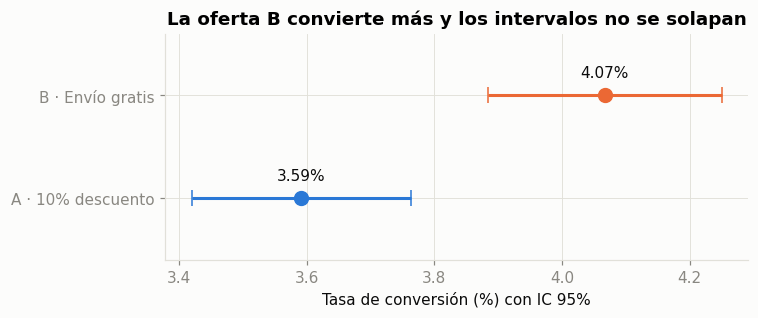

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
for i, v in enumerate(["A", "B"]):
    n, x = summary.loc[v, "visitantes"], summary.loc[v, "compradores"]
    p = x / n
    half = 1.96 * np.sqrt(p * (1 - p) / n)
    ax.errorbar(p * 100, i, xerr=half * 100, fmt="o", color=COLORS[v], ms=9, lw=2, capsize=5)
    ax.annotate(f"{p:.2%}", (p * 100, i), xytext=(0, 12), textcoords="offset points", ha="center", color=INK)
ax.set_yticks([0, 1], ["A · 10% descuento", "B · Envío gratis"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Tasa de conversión (%) con IC 95%")
ax.set_title("La oferta B convierte más y los intervalos no se solapan")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_conversion_ic.png")
plt.show()

## 4. Métricas secundarias: ¿se gana más dinero?

Convertir más no basta: la oferta B **no descuenta producto** pero la tienda **paga el envío** (4,90 €) en los pedidos ≥ 40 €.
Hay que mirar el ingreso y, sobre todo, el **beneficio por visitante**, que recoge ambos efectos.

El ingreso por visitante es una métrica muy asimétrica (≈96% de ceros), así que además del t-test de Welch se calcula un **IC bootstrap**, que no asume normalidad.

In [8]:
a, b = df[df.variant == "A"], df[df.variant == "B"]
metrics = {
    "Ingreso por visitante (€)": "revenue",
    "Beneficio por visitante (€)": "profit",
}
rows = []
boot_profit = None
for name, col in metrics.items():
    res = ab.welch_ttest(a[col], b[col], metric=name)
    lo, hi, boot = ab.bootstrap_mean_diff(a[col], b[col], n_boot=3_000, seed=1)
    if col == "profit":
        boot_profit = boot
    rows.append([name, res.value_a, res.value_b, res.rel_lift, f"[{res.ci_low:+.3f}, {res.ci_high:+.3f}]", f"[{lo:+.3f}, {hi:+.3f}]", res.p_value])

aov = ab.welch_ttest(a.loc[a.converted == 1, "revenue"], b.loc[b.converted == 1, "revenue"], metric="Ticket medio (€)")
rows.append([aov.metric, aov.value_a, aov.value_b, aov.rel_lift, f"[{aov.ci_low:+.2f}, {aov.ci_high:+.2f}]", "-", aov.p_value])

secondary = pd.DataFrame(rows, columns=["métrica", "A", "B", "lift", "IC 95% Welch", "IC 95% bootstrap", "p-valor"])
secondary.style.format({"A": "{:.3f}", "B": "{:.3f}", "lift": "{:+.1%}", "p-valor": "{:.2e}"})

,métrica,A,B,lift,IC 95% Welch,IC 95% bootstrap,p-valor
0,Ingreso por visitante (€),1.688,2.106,+24.8%,"[+0.278, +0.559]","[+0.273, +0.565]",4.86e-09
1,Beneficio por visitante (€),0.563,0.702,+24.8%,"[+0.092, +0.186]","[+0.090, +0.188]",6.66e-09
2,Ticket medio (€),46.992,51.793,+10.2%,"[+3.12, +6.48]",-,2.44e-08


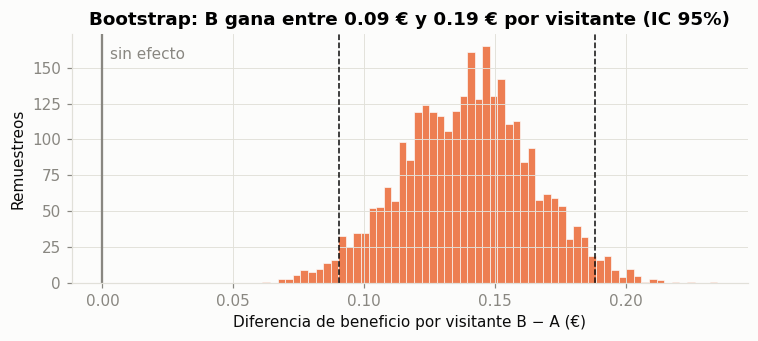

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(boot_profit, bins=60, color=COLORS["B"], alpha=0.85, edgecolor="#fcfcfb", linewidth=0.5)
lo, hi = np.quantile(boot_profit, [0.025, 0.975])
for x in (lo, hi):
    ax.axvline(x, color=INK, ls="--", lw=1)
ax.axvline(0, color=MUTED, lw=1.5)
ax.annotate("sin efecto", (0, ax.get_ylim()[1] * 0.9), xytext=(5, 0), textcoords="offset points", color=MUTED)
ax.set_xlabel("Diferencia de beneficio por visitante B − A (€)")
ax.set_ylabel("Remuestreos")
ax.set_title(f"Bootstrap: B gana entre {lo:.2f} € y {hi:.2f} € por visitante (IC 95%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_bootstrap_beneficio.png")
plt.show()

El ticket medio también sube en B: hay clientes que **añaden productos para llegar a los 40 €** del envío gratis.
Esto compensa el coste del envío y el beneficio por visitante sube ~25%.

## 5. Enfoque bayesiano

El p-valor responde a "¿qué probabilidad hay de ver estos datos si no hubiera efecto?". Negocio suele preguntar otra cosa:
**"¿qué probabilidad hay de que B sea mejor que A?"**. Con un modelo Beta-Binomial (prior uniforme) lo podemos responder directamente,
junto con la **pérdida esperada**: cuánta conversión perderíamos, de media, si eligiéramos la variante equivocada.

In [10]:
bayes = ab.bayesian_proportions(
    summary.loc["A", "compradores"], summary.loc["A", "visitantes"],
    summary.loc["B", "compradores"], summary.loc["B", "visitantes"],
)
print(f"P(B > A) = {bayes['prob_b_better']:.2%}")
print(f"Lift esperado: {bayes['lift_mean']:+.1%}  (intervalo de credibilidad 95%: {bayes['lift_ci'][0]:+.1%} a {bayes['lift_ci'][1]:+.1%})")
print(f"Pérdida esperada si elegimos A: {bayes['expected_loss_a'] * 100:.4f} pp")
print(f"Pérdida esperada si elegimos B: {bayes['expected_loss_b'] * 100:.4f} pp")

P(B > A) = 99.99%
Lift esperado: +13.3%  (intervalo de credibilidad 95%: +6.1% a +20.9%)
Pérdida esperada si elegimos A: 0.4756 pp
Pérdida esperada si elegimos B: 0.0000 pp


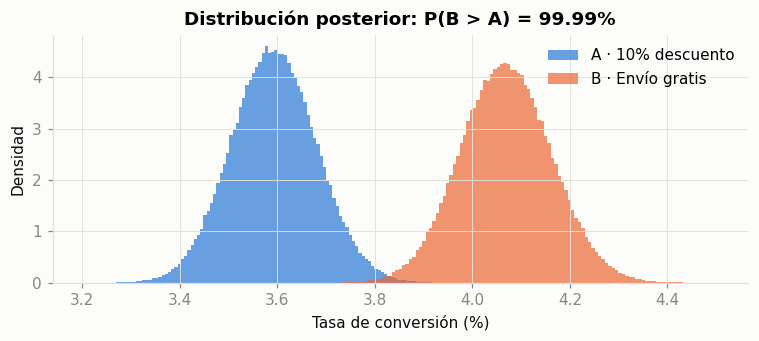

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for v, label in [("A", "A · 10% descuento"), ("B", "B · Envío gratis")]:
    ax.hist(bayes[f"samples_{v.lower()}"] * 100, bins=120, density=True, color=COLORS[v], alpha=0.7, label=label)
ax.set_xlabel("Tasa de conversión (%)")
ax.set_ylabel("Densidad")
ax.set_title(f"Distribución posterior: P(B > A) = {bayes['prob_b_better']:.2%}")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_posterior_bayesiana.png")
plt.show()

## 6. Análisis por segmentos

¿El efecto es igual para todos? Al hacer muchas comparaciones aumenta la probabilidad de encontrar un "falso positivo",
así que los p-valores se corrigen con **Holm-Bonferroni**. Este análisis es **exploratorio**: sirve para generar hipótesis, no para decidir.

In [12]:
seg_rows = []
for col in ["device", "user_type", "source"]:
    for level, sub in df.groupby(col):
        g = sub.groupby("variant")["converted"].agg(["sum", "size"])
        r = ab.two_proportion_ztest(g.loc["A", "sum"], g.loc["A", "size"], g.loc["B", "sum"], g.loc["B", "size"])
        seg_rows.append({
            "segmento": f"{col} = {level}", "n": len(sub), "conv_A": r.value_a, "conv_B": r.value_b,
            "lift": r.rel_lift, "lift_low": r.ci_low / r.value_a, "lift_high": r.ci_high / r.value_a, "p_valor": r.p_value,
        })
segments = pd.DataFrame(seg_rows)
segments["p_holm"] = ab.holm_correction(segments["p_valor"])
segments["significativo"] = segments["p_holm"] < 0.05
segments.style.format({"n": "{:,}", "conv_A": "{:.2%}", "conv_B": "{:.2%}", "lift": "{:+.1%}",
                       "lift_low": "{:+.1%}", "lift_high": "{:+.1%}", "p_valor": "{:.4f}", "p_holm": "{:.4f}"})

,segmento,n,conv_A,conv_B,lift,lift_low,lift_high,p_valor,p_holm,significativo
0,device = desktop,"34,163",4.55%,4.88%,+7.2%,-2.7%,+17.1%,0.1543,0.6171,False
1,device = mobile,"55,837",3.01%,3.57%,+18.7%,+8.9%,+28.6%,0.0002,0.0013,True
2,user_type = nuevo,"58,454",2.95%,3.14%,+6.6%,-2.9%,+16.0%,0.1716,0.6171,False
3,user_type = recurrente,"31,546",4.78%,5.79%,+21.2%,+10.9%,+31.6%,0.0001,0.0004,True
4,source = email,"10,759",5.21%,5.60%,+7.5%,-8.9%,+23.9%,0.3714,0.6171,False
5,source = organico,"36,133",3.86%,4.08%,+5.6%,-4.9%,+16.0%,0.2949,0.6171,False
6,source = paid,"27,038",2.95%,3.71%,+25.6%,+11.1%,+40.1%,0.0005,0.0033,True
7,source = social,"16,070",2.97%,3.62%,+22.0%,+3.4%,+40.6%,0.0201,0.1005,False


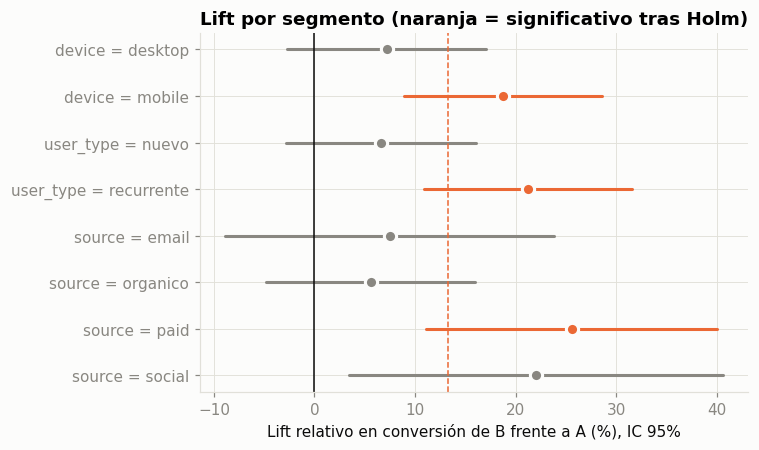

In [13]:
seg = segments.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7, 4.2))
for i, r in seg.iterrows():
    color = COLORS["B"] if r["significativo"] else MUTED
    ax.plot([r["lift_low"] * 100, r["lift_high"] * 100], [i, i], color=color, lw=2, solid_capstyle="round")
    ax.plot(r["lift"] * 100, i, "o", color=color, ms=8, mec="#fcfcfb", mew=2)
ax.axvline(0, color=INK, lw=1)
ax.axvline(conv.rel_lift * 100, color=COLORS["B"], ls="--", lw=1)
ax.annotate("lift global", (conv.rel_lift * 100, len(seg) - 0.4), xytext=(4, 0), textcoords="offset points", color=INK)
ax.set_yticks(range(len(seg)), seg["segmento"])
ax.set_xlabel("Lift relativo en conversión de B frente a A (%), IC 95%")
ax.set_title("Lift por segmento (naranja = significativo tras Holm)")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_lift_por_segmento.png")
plt.show()

Tras la corrección de Holm salen significativos **móvil**, **usuarios recurrentes** y **tráfico de pago**; en escritorio, usuarios nuevos,
email, orgánico y social el efecto es positivo pero no concluyente.

**Ojo con sobreinterpretar.** Como los datos son simulados sabemos la verdad: el efecto real solo cambia por **dispositivo**
(+17% en móvil, +4% en escritorio). Las diferencias entre recurrentes/nuevos o entre canales son en gran parte **ruido**. Es justo
lo que pasa en la vida real cuando se trocean los datos: aparecen "hallazgos" que no se replican. Por eso los segmentos sirven
para generar hipótesis que se confirman con un **nuevo test**, nunca para decidir con el test actual.

## 7. Evolución temporal y el peligro del *peeking*

Mirar los resultados cada día y parar en cuanto p < 0,05 infla mucho la tasa de falsos positivos. El gráfico muestra la conversión
acumulada: los primeros días es muy ruidosa y se estabiliza a medida que entra muestra. Por eso la duración se fija de antemano.

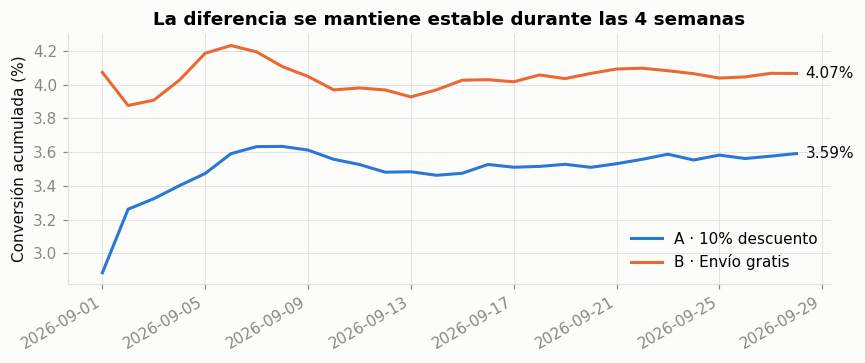

In [14]:
daily = df.groupby(["date", "variant"]).agg(conv=("converted", "sum"), n=("user_id", "size")).unstack("variant")
cum = daily.cumsum()
cum_cr = cum["conv"] / cum["n"] * 100

fig, ax = plt.subplots(figsize=(8, 3.4))
for v, label in [("A", "A · 10% descuento"), ("B", "B · Envío gratis")]:
    ax.plot(cum_cr.index, cum_cr[v], color=COLORS[v], lw=2, label=label)
    ax.annotate(f"{cum_cr[v].iloc[-1]:.2f}%", (cum_cr.index[-1], cum_cr[v].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK)
ax.set_ylabel("Conversión acumulada (%)")
ax.set_title("La diferencia se mantiene estable durante las 4 semanas")
ax.legend(frameon=False, loc="lower right")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_DIR / "05_conversion_acumulada.png")
plt.show()

## 8. Impacto de negocio estimado

In [15]:
monthly_visitors = 3_200 * 30
profit_a = summary.loc["A", "beneficio_por_visitante"]
profit_b = summary.loc["B", "beneficio_por_visitante"]
lo, hi = np.quantile(boot_profit, [0.025, 0.975])
print(f"Beneficio mensual estimado con A: {profit_a * monthly_visitors:,.0f} €")
print(f"Beneficio mensual estimado con B: {profit_b * monthly_visitors:,.0f} €")
print(f"Beneficio incremental: {(profit_b - profit_a) * monthly_visitors:+,.0f} €/mes "
      f"(IC 95%: {lo * monthly_visitors:+,.0f} € a {hi * monthly_visitors:+,.0f} €)")

Beneficio mensual estimado con A: 54,005 €
Beneficio mensual estimado con B: 67,384 €
Beneficio incremental: +13,379 €/mes (IC 95%: +8,686 € a +18,050 €)


## 9. Conclusión y recomendación

| Pregunta | Respuesta |
|---|---|
| ¿El experimento es válido? | Sí: sin SRM y con grupos balanceados |
| ¿B convierte más? | Sí: **+13% de lift relativo** (p < 0,001), IC 95% de la diferencia totalmente positivo |
| ¿B gana más dinero? | Sí: ingreso y **beneficio por visitante +25%**, pese a asumir el coste de envío |
| ¿Qué dice el enfoque bayesiano? | P(B > A) ≈ 100% y pérdida esperada de elegir B prácticamente nula |
| ¿Para quién funciona? | Sobre todo en **móvil**; en escritorio no hay evidencia suficiente (análisis exploratorio) |

**Recomendación: lanzar la oferta "Envío gratis en pedidos ≥ 40 €" al 100% del tráfico.**

Siguientes pasos:
1. Monitorizar el beneficio por visitante tras el lanzamiento (posible efecto novedad).
2. Testear el umbral del envío gratis (35 € vs 40 € vs 50 €), ya que es lo que impulsa el ticket medio.
3. En escritorio, probar ofertas alternativas específicas, ya que el envío gratis no muestra un efecto claro.

**Validación del método:** los datos se simularon con un lift real del +17% en móvil y +4% en escritorio. El análisis recupera
ese patrón (efecto fuerte en móvil, débil y no significativo en escritorio) y estima un lift global (+13%) coherente con el real.
También ilustra un riesgo: algunos segmentos sin efecto diferencial real (recurrentes, tráfico de pago) salen significativos por azar.